# 阶段 1 作业

题目、你的代码、你的答案都写在这个笔记本里。做完保存，告诉我「批改」。

满分 100：简单 10 + 中等 30 + 中等 30 + 困难 30。

- 先跑完第 1、2 课，同目录下要有 `micrograd.py` 和 `nn.py`。
- API 和写法直接写在题目里；每题有一个折叠的提示，卡住再点开。
- **文字答案请用自己的话写，带上你跑出来的数字。**

In [3]:
import math
import random

import matplotlib.pyplot as plt

from micrograd import Value
from nn import MLP

plt.rcParams["font.sans-serif"] = ["Arial Unicode MS"]

---
## 简单题 · 一个数用了两次（10 分）

```python
a = Value(2.0)
b = Value(-3.0)
d = a * b + a
d.backward()
```

1. 先**不运行**，手算 `a.grad` 和 `b.grad`，写出推导过程。
2. 在代码格里运行验证。
3. 引擎里所有 `_backward` 都用 `+=` 往 `.grad` 上加。如果把它们全换成 `=`，`a.grad` 会变成多少？为什么会错？（不用真的改代码，推一下就行）

<details><summary>提示</summary>

a 出现在两个地方：乘法里一次、加法里一次。a 动一点点，d 会从两条路同时变化。

</details>

**你的答案**（先别运行代码）：

1. 推导：
a.grad =b.data + 1 = -2;也就是d对a的导数，来自于求导法则a*b这里对a求导是b，后面的a求导是1，然后相加。下面同理。
b.grad = a.data = 2.
2. 验证结果：结果正确，就是-2.0 2.0。
3. 换成 `=` 之后：换成等号之后，a.grad = -3, 因为后面的+1，初始梯度没有了，其他路的导数不在了。

In [4]:
# 验证
a = Value(2.0)
b = Value(-3.0)
d = a * b + a
d.backward()
print(a.grad, b.grad)

-2.0 2.0


---
## 中等题 1 · 给引擎加新运算（30 分）

给 `Value` 加两个新运算，再写一个**梯度检查**，确认你算的导数是对的。

1. **`exp`**：输出 eˣ，导数也是 eˣ。
2. **`relu`**：x > 0 时输出 x，否则输出 0。导数：x > 0 时是 1，否则是 0。它是现在神经网络里最常用的激活函数之一。
3. **梯度检查**：对下面这个函数，分别用 `backward()` 和「挪一点点去量」（h = 1e-6）算出 a、b 的导数，打印两边的差，应该小于 1e-4：

   ```python
   def F(a, b):
       return (a * b).exp() + (b - a).relu() * a
   ```

   取 a = 0.5，b = 1.5。数值导数那边，直接把普通 Python 数字传进 `Value` 再取 `.data` 就行。
4. **思考**：relu 在 x = 0 这一点的导数，你的代码给的是多少？如果用数值导数去量 x = 0 这一点，往右挪 h 和往左挪 h，各量出多少？

**要用到的写法**：在类外面定义一个函数，再挂到类上，就等于给类加了个方法：

```python
def exp(self):
    out = Value(math.exp(self.data), (self,), "exp")

    def _backward():
        self.grad += ...  # 你来填：局部导数 × out.grad

    out._backward = _backward
    return out


Value.exp = exp  # 从此每个 Value 都能 .exp()
```

<details><summary>提示</summary>

exp 的 `_backward` 里，局部导数 eˣ 就是 `out.data`，不用再算一次。relu 的导数要看 `self.data` 是否大于 0。

</details>

In [7]:
# 1、2：exp 和 relu
def exp(self):
    out = Value(math.exp(self.data), (self,), "exp")

    def _backward():
        self.grad += out.data * out.grad  # 你来填：局部导数 × out.grad
    
    out._backward = _backward
    return out
def relu(self):
    out = Value(max(0, self.data), (self,), "ReLU")
    
    def _backward():
        self.grad +=(self.data > 0) * out.grad

    out._backward = _backward

    return out

Value.exp = exp
Value.relu = relu

In [12]:
# 3：梯度检查
def F(a,b):
    return (a*b).exp() + (b-a).relu() *a

def F_num(a,b):
    return F(Value(a), Value(b)).data


a0, b0 = 0.5, 1.5
h = 1e-6
# 1、自动求导
a = Value(a0)
b = Value(b0)

out = F(a,b)
out.backward()

# 数f0 = F_num(a0, b0)
f0 = F_num(a0, b0)
da_num = (F_num(a0 + h, b0) - f0)/h
db_num = (F_num(a0, b0 + h) - f0)/h

# 3. 比较两种方法
err_a = abs(a.grad - da_num)
err_b = abs(b.grad - db_num)

print(f"a：自动求导={a.grad:.8f}，数值求导={da_num:.8f}，差={err_a:.2e}")
print(f"b：自动求导={b.grad:.8f}，数值求导={db_num:.8f}，差={err_b:.2e}")

assert err_a < 1e-4
assert err_b < 1e-4
print("梯度检查通过！")

a：自动求导=3.67550002，数值求导=3.67550141，差=1.38e-06
b：自动求导=1.55850001，数值求导=1.55850027，差=2.65e-07
梯度检查通过！


**你的答案：**

- 梯度检查结果（两边的差）：
- relu 在 x = 0 处，代码给的导数：
- 数值导数往右挪 / 往左挪：

---
## 中等题 2 · 学习率和清零实验（30 分）

用第 2 课的数据和 `MLP(3, [4, 4, 1])`：

1. 学习率分别取 **0.001、0.05、0.5、2.0**，各训练 50 步，把 4 条 loss 曲线画在**同一张图**上。每次建模型前都写 `random.seed(42)`，保证 4 次的初始参数一样，比较才公平。
2. 描述每条曲线的样子。学习率太小、太大分别会怎样？为什么？
3. 学习率用 0.05，**去掉清零梯度那一步**，分别用两组答案各训练 50 步，每组都和正常训练（有清零）的曲线画在一起比较：
   - 原来的答案 `ys = [1.0, -1.0, -1.0, 1.0]`
   - 缩小一半的答案 `ys_half = [0.5, -0.5, -0.5, 0.5]`

   两组结果有什么不同？为什么答案是 ±1 时，不清零「看起来没问题」？

**要用到的写法**：

```python
xs = [[2.0, 3.0, -1.0], [3.0, -1.0, 0.5], [0.5, 1.0, 1.0], [1.0, 1.0, -1.0]]
ys = [1.0, -1.0, -1.0, 1.0]

plt.plot(losses, label="lr=0.05")  # label 是图例里的名字
plt.yscale("log")                   # 纵轴用对数刻度，大小差很多的曲线也能看清
plt.legend()                        # 显示图例
plt.show()
```

建议把训练循环包成一个函数，比如 `train(ys, lr, steps=50, zero_grad=True)`，返回 losses 列表，后面调几次就行。

<details><summary>提示</summary>

学习率是「每步挪多远」。想象在山谷里往下走：步子太小要走很久；步子太大可能跨过头，也可能一步跳到一片平地上，梯度几乎为 0，再也走不动（想想 tanh 两头是不是平的）。不清零的话，每一步实际挪的距离是 lr × 到目前为止**所有梯度的总和**，越积越大。

</details>

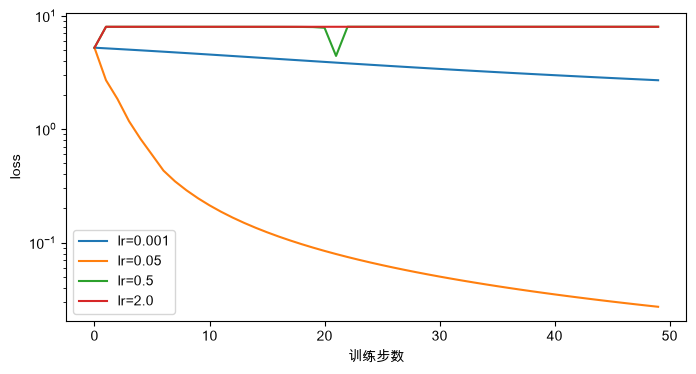

学习率 0.001：5.23052 → 2.70168
学习率 0.05：5.23052 → 0.0271687
学习率 0.5：5.23052 → 7.99994
学习率 2.0：5.23052 → 8
目标 ±1.0：清零=0.0271687，不清零=1.18605e-21
目标 ±0.5：清零=0.00357667，不清零=0.338152


In [22]:
# 1：四种学习率
# 1.1 准备数据：
xs = [
    [2.0, 3.0, -1.0],
    [3.0, -1.0, 0.5],
    [0.5, 1.0, 1.0],
    [1.0, 1.0, -1.0],
]
ys = [1.0, -1.0, -1.0, 1.0]
# 1.2 设置训练循环

def train(ys, lr, steps = 50, zero_grad = True):
    random.seed(42)
    model  = MLP(3,[4,4,1])
    losses = []

    for step in range(steps):
        # 计算前向的loss
        ypred = [model(x) for x in xs]
        loss = sum((yp - yt) ** 2 for yp, yt in zip(ypred, ys))

        # 用开关决定是否清零
        if zero_grad:
            for p in model.parameters():
                p.grad = 0.0

        loss.backward()

        for p in model.parameters():
            p.data -= lr * p.grad

        losses.append(loss.data)

    return losses

#1.3 准备不同的学习率：
plt.figure(figsize=(8,4))

for lr in [0.001, 0.05, 0.5, 2.0]:
    losses = train(ys, lr=lr)
    plt.plot(losses, label=f"lr={lr}")
plt.yscale('log')
plt.xlabel("训练步数")
plt.ylabel("loss")
plt.legend()
plt.show()

for lr in [0.001, 0.05, 0.5, 2.0]:
    losses = train(ys, lr=lr)
    print(f"学习率 {lr}：{losses[0]:.6g} → {losses[-1]:.6g}")

ys_half = [0.5, -0.5, -0.5, 0.5]

for targets in [ys, ys_half]:
    normal = train(targets, lr=0.05, zero_grad=True)
    no_zero = train(targets, lr=0.05, zero_grad=False)
    print(
        f"目标 ±{targets[0]}："
        f"清零={normal[-1]:.6g}，不清零={no_zero[-1]:.6g}"
    )

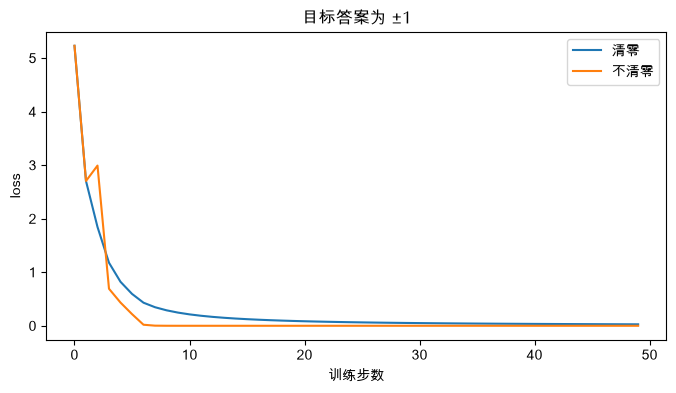

最后记录的 loss： 0.02716870157235618 1.1860532572110626e-21


In [17]:
# 3：去掉清零
normal = train(ys, lr=0.05, zero_grad=True)
no_zero = train(ys, lr=0.05, zero_grad=False)

plt.figure(figsize=(8, 4))
plt.plot(normal, label="清零")
plt.plot(no_zero, label="不清零")
plt.xlabel("训练步数")
plt.ylabel("loss")
plt.title("目标答案为 ±1")
plt.legend()
plt.show()

print("最后记录的 loss：", normal[-1], no_zero[-1])

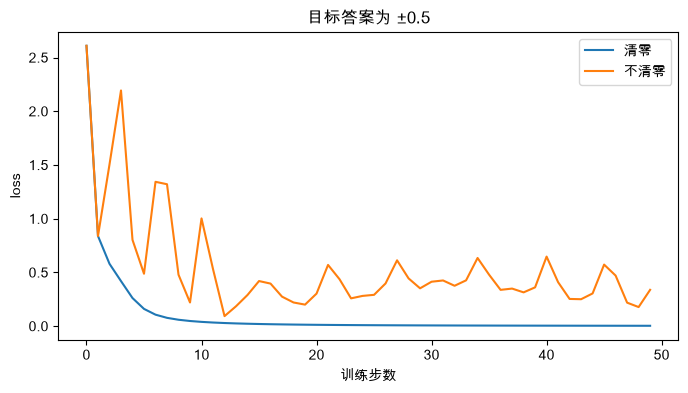

最后记录的 loss： 0.0035766670777472175 0.33815151024446843


In [18]:
ys_half = [0.5, -0.5, -0.5, 0.5]

normal = train(ys_half, lr=0.05, zero_grad=True)
no_zero = train(ys_half, lr=0.05, zero_grad=False)

plt.figure(figsize=(8, 4))
plt.plot(normal, label="清零")
plt.plot(no_zero, label="不清零")
plt.xlabel("训练步数")
plt.ylabel("loss")
plt.title("目标答案为 ±0.5")
plt.legend()
plt.show()

print("最后记录的 loss：", normal[-1], no_zero[-1])

**你的答案：**

- 0.001：5.23052 → 2.70168
- 0.05：5.23052 → 0.0271687
- 0.5：5.23052 → 7.99994
- 2.0：5.23052 → 8
- 太小 / 太大的问题：学习率太小，每次参数变化很小，收敛慢；太大可能越过合适的位置。这次实验里，大步更新把 tanh 推到两端平坦的区域，梯度很小，后续很难调整回来
- 去掉清零，答案 ±1：正常训练最后的 loss 约 0.02717；不清零时反而接近 0，表面上效果更好。
- 去掉清零，答案 ±0.5：正常训练最后的 loss 约 0.00358；不清零时约 0.33815，曲线有明显波动，效果差很多。
- 为什么 ±1 时「看起来没问题」：不清零会让历史梯度留在 .grad 中，持续影响参数更新。在这次实验中，它把输出推向 tanh 的两端，也就是接近 ±1，碰巧符合目标，所以 loss 很小。目标换成 ±0.5 时，输出需要停在中间，继续往两端推就会偏离目标。

---
## 困难思考题 · 为什么不能用这个引擎训练大模型（30 分）

1. **数节点**：对 4 个样本做一次前向、算出 loss，计算图里一共有多少个 `Value` 节点？用下面的函数数一下。按这个比例粗略估一下：如果模型有 1750 亿个参数（GPT-3），每个样本要建多少个节点？PyTorch 为什么让一个节点代表**一整个张量运算**（比如一次矩阵乘法），而不是一个数？

   ```python
   def count_nodes(root):
       seen, stack = set(), [root]
       while stack:
           v = stack.pop()
           if v not in seen:
               seen.add(v)
               stack.extend(v._prev)
       return len(seen)
   ```

2. **中间结果**：看引擎里的 `_backward`：乘法要用前向时的 `other.data`，tanh 要用前向时算出的 `t`。所以前向的中间结果在 `backward()` 之前都不能扔。结合阶段 0 算过的内存账，说说为什么**训练**比**推理**占的内存多得多。推理时可以不存这些中间结果吗？

<details><summary>提示</summary>

第 1 问：参数只有 41 个，但每个样本过网络时，每次加法、乘法、tanh 都会新建节点，4 个样本各建一套。第 2 问：训练时内存里同时要有哪几样东西？推理只需要往前算出答案，还需要往回传吗？

</details>

In [24]:
# 第 1 问：数节点
def count_nodes(root):
    seen = set()       # 已经数过的节点
    stack = [root]     # 接下来要检查的节点

    while stack:
        v = stack.pop()

        if v not in seen:
            seen.add(v)
            stack.extend(v._prev)

    return len(seen)

random.seed(42)
model = MLP(3, [4, 4, 1])

xs = [
    [2.0, 3.0, -1.0],
    [3.0, -1.0, 0.5],
    [0.5, 1.0, 1.0],
    [1.0, 1.0, -1.0],
]
ys = [1.0, -1.0, -1.0, 1.0]

ypred = [model(x) for x in xs]
loss = sum((yp - yt) ** 2 for yp, yt in zip(ypred, ys))

print("参数个数：", len(model.parameters()))
print("计算图节点数：", count_nodes(loss))

参数个数： 41
计算图节点数： 470


In [27]:
single_loss = (ypred[0] - ys[0]) ** 2

print("单个样本的节点数：", count_nodes(single_loss))

big_params = 175_000_000_000
estimate = big_params * count_nodes(single_loss) / len(model.parameters())

print(f"估计节点数：{estimate:.3e}")
print(f"约 {estimate / 1e8:.0f} 亿个节点")
# 按这个小网络的比例粗略放大，一个样本的图就会达到数千亿个节点。 这个估算包含参数节点，只用于说明数量级；真实大模型的结构、序列长度等都会改变比例。

单个样本的节点数： 147
估计节点数：6.274e+11
约 6274 亿个节点


**你的答案：**

1.参数的个数是41个。计算图节点是470个。当前模型有 41 个参数，四个样本做前向并计算总 loss 后，共有 470 个 Value 节点。单个样本的预测和平方误差图有 147 个节点，按这个比例放大到 1750 亿参数，约为 \(6.27\times10^{11}\) 个节点。标量引擎会产生大量 Python 对象和函数调用，存储和执行成本过高；PyTorch 以张量运算为单位组织自动求导，减少这些额外开销，并使用底层计算库批量计算。
2.中间结果： 训练除了保存参数，还需要参数梯度、反向传播所需的前向数据，以及可能的优化器状态。例如乘法求导要用输入值，tanh 求导要用前向输出，所以这些数据不能在反向用到之前直接丢弃。推理不更新参数，不需要反向传播，因此可以在中间数据不再被后续前向计算使用时释放它们，但仍然需要参数和计算过程中的临时内存。